In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/laotse/credit-risk-dataset/credit_risk_dataset.csv


In [2]:
import os
import numpy as np
import pandas as pd

# 1. العثور التلقائي على ملف البيانات في بيئة Kaggle
csv_files = []
for dirname, _, filenames in os.walk('/kaggle/input'):
  for filename in filenames:
    if filename.endswith('.csv'):
      csv_files.append(os.path.join(dirname, filename))

print('الملفات المكتشفة:', csv_files)
df = pd.read_csv(csv_files[0])

# 2. التقرير الجراحي الأول للبيانات (ML Lecture 1 & 2)
print(
    f'\n[1] أبعاد البيانات: {df.shape[0]:,} صف (عينة) × {df.shape[1]} عمود'
    ' (ميزة)'
)
print(f'[2] عدد الصفوف المكررة بالكامل: {df.duplicated().sum()}')

print('\n[3] ملخص أنواع الأعمدة والقيم المفقودة:')
summary_df = pd.DataFrame({
    'نوع_البيانات (Dtype)': df.dtypes,
    'القيم_المفقودة (Nulls)': df.isnull().sum(),
    'نسبة_الفقد (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'عدد_القيم_الفريدة (Unique)': df.nunique(),
    'عينة_أولى': df.iloc[0].values,
})
print(summary_df)

print('\n[4] الإحصاءات الوصفية للأعمدة الرقمية (لرصد القيم الشاذة):')
print(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

الملفات المكتشفة: ['/kaggle/input/datasets/laotse/credit-risk-dataset/credit_risk_dataset.csv']

[1] أبعاد البيانات: 32,581 صف (عينة) × 12 عمود (ميزة)
[2] عدد الصفوف المكررة بالكامل: 165

[3] ملخص أنواع الأعمدة والقيم المفقودة:
                           نوع_البيانات (Dtype)  القيم_المفقودة (Nulls)  \
person_age                                int64                       0   
person_income                             int64                       0   
person_home_ownership                    object                       0   
person_emp_length                       float64                     895   
loan_intent                              object                       0   
loan_grade                               object                       0   
loan_amnt                                 int64                       0   
loan_int_rate                           float64                    3116   
loan_status                               int64                       0   
loan_percent_income   

حجم البيانات قبل التنظيف: 32,581 صف
بعد حذف الـ 165 صفاً المكررة: 32,416 صف
عدد الصفوف ذات الأعمار/سنوات العمل المستحيلة: 7
       person_age  person_emp_length  person_income  loan_status
0              22              123.0          59000            1
81            144                4.0         250000            0
183           144                4.0         200000            0
210            21              123.0         192000            0
575           123                2.0          80004            0
747           123                7.0          78000            0
32297         144               12.0        6000000            0
حجم البيانات النظيفة النهائي: 32,409 صف

=== نسبة التعثر (%) حسب التصنيف الائتماني (loan_grade) ===
loan_grade
A     9.96
B    16.32
C    20.76
D    59.05
E    64.49
F    70.54
G    98.44
Name: loan_status, dtype: float64

=== نسبة التعثر (%) حسب ملكية السكن (person_home_ownership) ===
person_home_ownership
MORTGAGE    12.62
OTHER       31.13
OWN        

/tmp/ipykernel_48/2618171955.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_48/2618171955.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_48/2618171955.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_48/2618171955.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


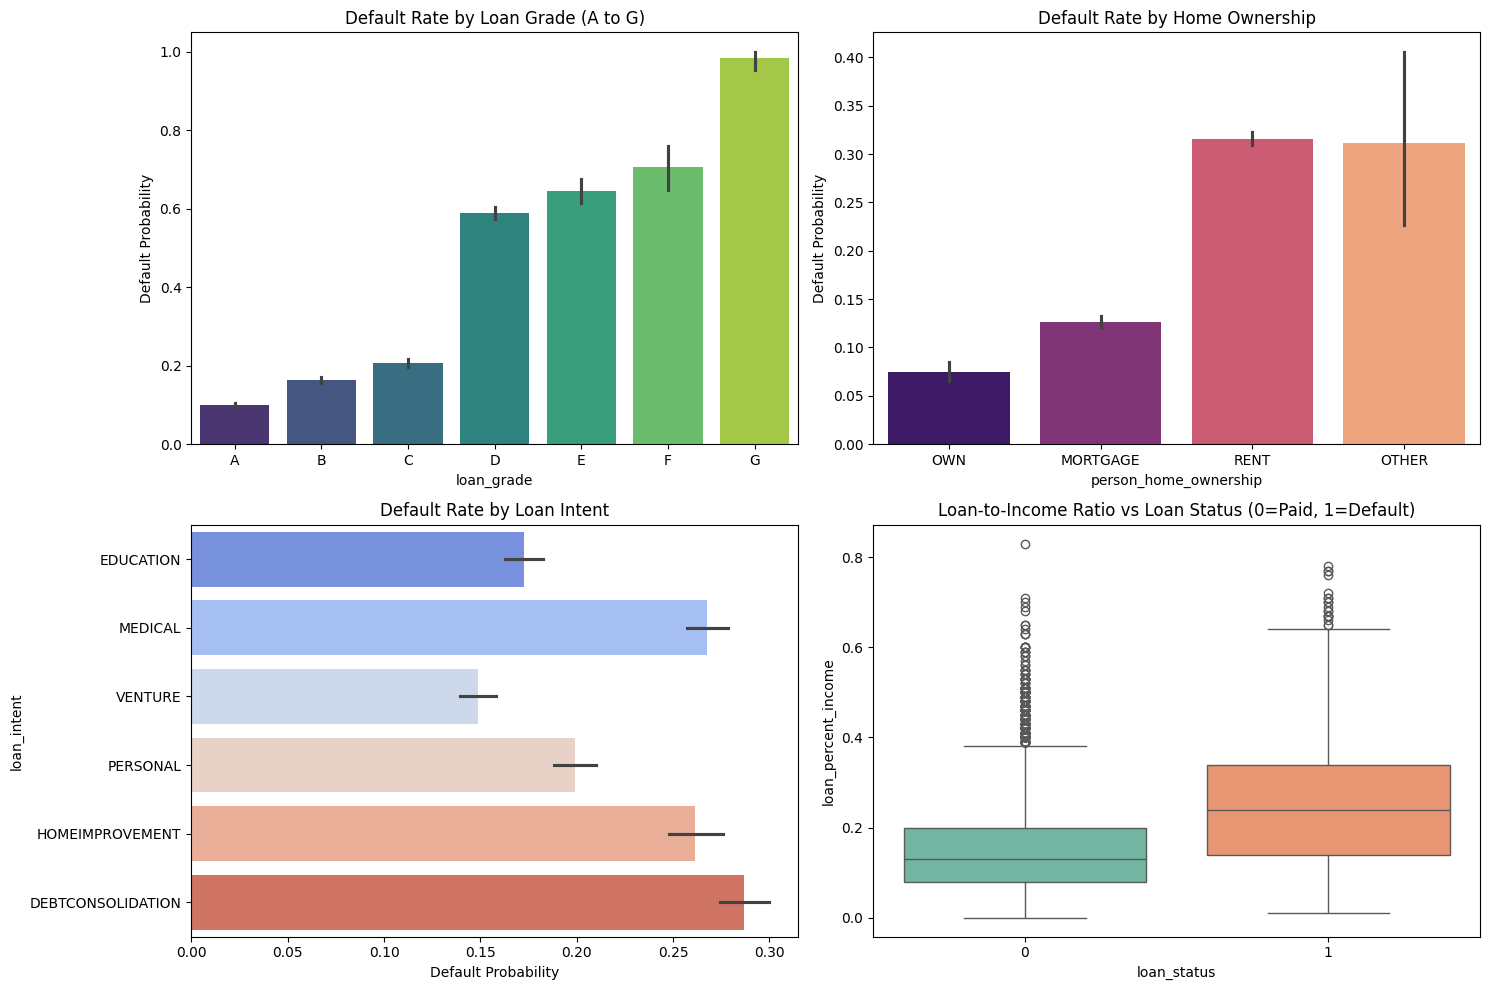

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

print(f'حجم البيانات قبل التنظيف: {df.shape[0]:,} صف')

# 1. حذف الصفوف المكررة بالكامل
df_clean = df.drop_duplicates().copy()
print(f'بعد حذف الـ 165 صفاً المكررة: {df_clean.shape[0]:,} صف')

# 2. فحص وحذف الأعمار وسنوات العمل المستحيلة منطقياً (Outliers Cleaning)
impossible_mask = (
    (df_clean['person_age'] > 100)
    | (df_clean['person_emp_length'] > 60)
    | (df_clean['person_emp_length'] > (df_clean['person_age'] - 14))
)
print(f'عدد الصفوف ذات الأعمار/سنوات العمل المستحيلة: {impossible_mask.sum()}')
print(
    df_clean[impossible_mask][
        ['person_age', 'person_emp_length', 'person_income', 'loan_status']
    ]
)

df_clean = df_clean[~impossible_mask].reset_index(drop=True)
print(f'حجم البيانات النظيفة النهائي: {df_clean.shape[0]:,} صف\n')

# 3. تحليل نسب التعثر حسب الفئات (لكي نفهم سلوك المقترضين)
print('=== نسبة التعثر (%) حسب التصنيف الائتماني (loan_grade) ===')
print((df_clean.groupby('loan_grade')['loan_status'].mean() * 100).round(2))

print('\n=== نسبة التعثر (%) حسب ملكية السكن (person_home_ownership) ===')
print(
    (
        df_clean.groupby('person_home_ownership')['loan_status'].mean() * 100
    ).round(2)
)

print('\n=== نسبة التعثر (%) حسب الغرض من القرض (loan_intent) ===')
print(
    (df_clean.groupby('loan_intent')['loan_status'].mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

# 4. رسم لوحة الاستكشاف البصري (EDA Visual Dashboard)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# الرسم 1: نسبة التعثر حسب التصنيف الائتماني
grade_order = sorted(df_clean['loan_grade'].unique())
sns.barplot(
    data=df_clean,
    x='loan_grade',
    y='loan_status',
    order=grade_order,
    ax=axes[0, 0],
    palette='viridis',
)
axes[0, 0].set_title('Default Rate by Loan Grade (A to G)', fontsize=12)
axes[0, 0].set_ylabel('Default Probability')

# الرسم 2: نسبة التعثر حسب ملكية المنزل
sns.barplot(
    data=df_clean,
    x='person_home_ownership',
    y='loan_status',
    ax=axes[0, 1],
    palette='magma',
)
axes[0, 1].set_title('Default Rate by Home Ownership', fontsize=12)
axes[0, 1].set_ylabel('Default Probability')

# الرسم 3: نسبة التعثر حسب الغرض من القرض
sns.barplot(
    data=df_clean,
    y='loan_intent',
    x='loan_status',
    ax=axes[1, 0],
    palette='coolwarm',
)
axes[1, 0].set_title('Default Rate by Loan Intent', fontsize=12)
axes[1, 0].set_xlabel('Default Probability')

# الرسم 4: علاقة نسبة القرض من الدخل بالتعثر
sns.boxplot(
    data=df_clean,
    x='loan_status',
    y='loan_percent_income',
    ax=axes[1, 1],
    palette='Set2',
)
axes[1, 1].set_title(
    'Loan-to-Income Ratio vs Loan Status (0=Paid, 1=Default)', fontsize=12
)

plt.tight_layout()
plt.show()

In [4]:
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

# 1. فصل الميزات (X) عن الهدف (y)
X = df_clean.drop(columns=['loan_status']).copy()
y = df_clean['loan_status'].copy()

# 2. التقسيم الثلاثي الصارم (64% Train, 16% Val, 20% Test) قبل أي تعويض أو تقييس لمنع Data Leakage
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=SEED
)

print(
    f'أحجام الأقسام -> التدريب: {X_train.shape[0]:,} | التحقق:'
    f' {X_val.shape[0]:,} | الاختبار: {X_test.shape[0]:,}'
)

# 3. تعويض القيم المفقودة (Imputation) محسوباً من التدريب فقط!
num_cols_with_nulls = ['person_emp_length', 'loan_int_rate']
imputer = SimpleImputer(strategy='median')

# إضافة مؤشرات الفقد قبل التعويض ثم تطبيق الوسيط
for split_df in [X_train, X_val, X_test]:
  split_df['emp_length_missing'] = (
      split_df['person_emp_length'].isnull().astype(int)
  )
  split_df['int_rate_missing'] = split_df['loan_int_rate'].isnull().astype(int)

X_train[num_cols_with_nulls] = imputer.fit_transform(
    X_train[num_cols_with_nulls]
)
X_val[num_cols_with_nulls] = imputer.transform(X_val[num_cols_with_nulls])
X_test[num_cols_with_nulls] = imputer.transform(X_test[num_cols_with_nulls])


# 4. دالة هندسة الميزات المالية الذكية (Domain Feature Engineering)
def engineer_financial_features(data):
  d = data.copy()
  # أ. تحويل التصنيف الائتماني A-G إلى سلم رقمي 1-7
  grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
  d['grade_num'] = d['loan_grade'].map(grade_map)

  # ب. تحويل التعثر السابق Y/N إلى 1/0
  d['prior_default_binary'] = (d['cb_person_default_on_file'] == 'Y').astype(
      int
  )

  # ج. عبء الفائدة السنوي بالدولار ونسبة العبء الكلي من الدخل
  d['annual_interest_cost'] = d['loan_amnt'] * (d['loan_int_rate'] / 100.0)
  d['total_burden_to_income'] = (
      d['loan_amnt'] + d['annual_interest_cost']
  ) / (d['person_income'] + 1.0)

  # د. القوة المالية للعمر ونسبة الاستقرار الوظيفي
  d['income_per_age'] = d['person_income'] / d['person_age']
  d['emp_stability_ratio'] = d['person_emp_length'] / np.maximum(
      d['person_age'] - 18, 1
  )

  # هـ. معالجة الالتواء الشديد في الدخل ومبلغ القرض باللوغاريتم (Log Transform)
  d['log_income'] = np.log1p(d['person_income'])
  d['log_loan_amnt'] = np.log1p(d['loan_amnt'])
  return d


X_train_fe = engineer_financial_features(X_train)
X_val_fe = engineer_financial_features(X_val)
X_test_fe = engineer_financial_features(X_test)

# 5. ترميز المتغيرات الفئوية (One-Hot Encoding) ومطابقة الأعمدة
cat_cols = [
    'person_home_ownership',
    'loan_intent',
    'loan_grade',
    'cb_person_default_on_file',
]
X_train_enc = pd.get_dummies(X_train_fe, columns=cat_cols, drop_first=True)
X_val_enc = pd.get_dummies(X_val_fe, columns=cat_cols, drop_first=True)
X_test_enc = pd.get_dummies(X_test_fe, columns=cat_cols, drop_first=True)

X_val_enc = X_val_enc.reindex(columns=X_train_enc.columns, fill_value=0)
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

# 6. التقييس (StandardScaler) محسوباً من التدريب فقط
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_enc)
X_val_scaled = scaler.transform(X_val_enc)
X_test_scaled = scaler.transform(X_test_enc)

# 7. إثراء البيانات بالتعلم غير الخاضع للإشراف (K-Means Clustering - ML Lecture 7)
kmeans = KMeans(n_clusters=4, random_state=SEED, n_init=10)
train_clusters = kmeans.fit_predict(X_train_scaled)
val_clusters = kmeans.predict(X_val_scaled)
test_clusters = kmeans.predict(X_test_scaled)

# إضافة شرائح K-Means كميزات إضافية
for i in range(4):
  X_train_enc[f'cluster_{i}'] = (train_clusters == i).astype(int)
  X_val_enc[f'cluster_{i}'] = (val_clusters == i).astype(int)
  X_test_enc[f'cluster_{i}'] = (test_clusters == i).astype(int)

# إعادة التقييس النهائي بعد إضافة الشرائح لتكون جاهزة للشبكة العصبية والـ ML
final_scaler = StandardScaler()
X_train_final = final_scaler.fit_transform(X_train_enc)
X_val_final = final_scaler.transform(X_val_enc)
X_test_final = final_scaler.transform(X_test_enc)

print(
    '\nعدد الميزات الأصلي: 11 ميزة -> عدد الميزات بعد الهندسة المالية و'
    f' K-Means: {X_train_enc.shape[1]} ميزة!'
)
print('\n=== تحليل شرائح العملاء المكتشفة بواسطة K-Means (في بيانات التدريب) ===')
cluster_summary = pd.DataFrame({
    'Cluster': train_clusters,
    'Income': X_train['person_income'].values,
    'Loan_Amnt': X_train['loan_amnt'].values,
    'Int_Rate': X_train['loan_int_rate'].values,
    'Default_Rate (%)': y_train.values * 100,
})
print(cluster_summary.groupby('Cluster').mean().round(2))

أحجام الأقسام -> التدريب: 20,741 | التحقق: 5,186 | الاختبار: 6,482

عدد الميزات الأصلي: 11 ميزة -> عدد الميزات بعد الهندسة المالية و K-Means: 36 ميزة!

=== تحليل شرائح العملاء المكتشفة بواسطة K-Means (في بيانات التدريب) ===
            Income  Loan_Amnt  Int_Rate  Default_Rate (%)
Cluster                                                  
0         61028.32    9717.70     14.23             36.90
1         51698.10   14917.65     11.66             40.25
2         49248.18    5462.08      9.79             12.97
3        126027.97   12652.25     10.16              5.70


=== جدول مقارنة نماذج تعلم الآلة (ML Models Comparison) ===
                            Model  Train_Acc (%)  Val_Acc (%)  Val_ROC_AUC  Val_Precision (%)  Val_Recall (%)  Val_F1
1. Logistic Regression (Baseline)          87.26        87.33       0.8849              78.70           57.67  0.6656
       2. Random Forest (Bagging)          93.89        91.98       0.9253              94.21           67.46  0.7862
  3. Gradient Boosting (Boosting)          95.15        93.02       0.9458              95.20           71.69  0.8179

=== أهم 12 ميزة مؤثرة في اكتشاف تعثر القروض (Top 12 Features) ===
total_burden_to_income         26.56
grade_num                      20.15
person_home_ownership_RENT     15.62
person_income                   7.25
log_income                      4.90
loan_percent_income             4.02
person_emp_length               2.97
loan_intent_MEDICAL             2.43
loan_intent_HOMEIMPROVEMENT     2.08
loan_int_rate                   1.75
loan_intent_PERSONAL           

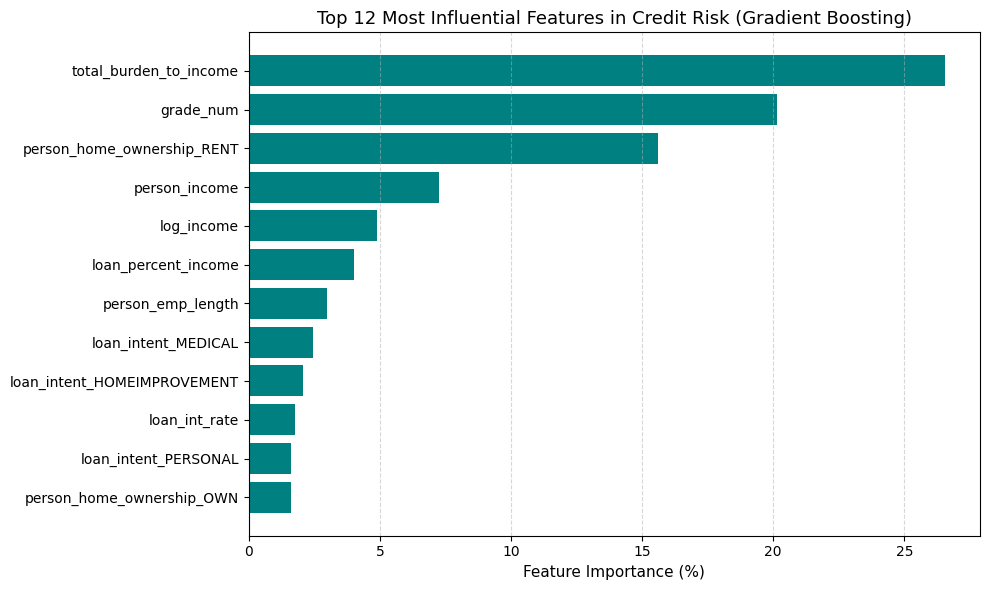

In [5]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

# 1. تعريف نماذج تعلم الآلة الكلاسيكية (ML Lectures 4, 5, 6)
ml_models = {
    '1. Logistic Regression (Baseline)': LogisticRegression(
        max_iter=1000, random_state=SEED
    ),
    '2. Random Forest (Bagging)': RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=5, random_state=SEED, n_jobs=-1
    ),
    '3. Gradient Boosting (Boosting)': GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=5, random_state=SEED
    ),
}

# 2. تدريب النماذج ومقارنة أدائها على التدريب والتحقق
ml_results = []
trained_ml_models = {}

for name, model in ml_models.items():
  model.fit(X_train_final, y_train)
  trained_ml_models[name] = model

  # توقعات التدريب والتحقق
  train_preds = model.predict(X_train_final)
  train_probs = model.predict_proba(X_train_final)[:, 1]

  val_preds = model.predict(X_val_final)
  val_probs = model.predict_proba(X_val_final)[:, 1]

  ml_results.append({
      'Model': name,
      'Train_Acc (%)': round(accuracy_score(y_train, train_preds) * 100, 2),
      'Val_Acc (%)': round(accuracy_score(y_val, val_preds) * 100, 2),
      'Val_ROC_AUC': round(roc_auc_score(y_val, val_probs), 4),
      'Val_Precision (%)': round(
          precision_score(y_val, val_preds) * 100, 2
      ),
      'Val_Recall (%)': round(recall_score(y_val, val_preds) * 100, 2),
      'Val_F1': round(f1_score(y_val, val_preds), 4),
  })

results_df = pd.DataFrame(ml_results)
print('=== جدول مقارنة نماذج تعلم الآلة (ML Models Comparison) ===')
print(results_df.to_string(index=False))

# 3. استخراج ورسم أهم 12 ميزة من نموذج Gradient Boosting (Feature Importance)
gb_model = trained_ml_models['3. Gradient Boosting (Boosting)']
importances = pd.Series(
    gb_model.feature_importances_, index=X_train_enc.columns
).sort_values(ascending=False)

print('\n=== أهم 12 ميزة مؤثرة في اكتشاف تعثر القروض (Top 12 Features) ===')
print((importances.head(12) * 100).round(2))

plt.figure(figsize=(10, 6))
top12 = importances.head(12).sort_values(ascending=True) * 100
plt.barh(top12.index, top12.values, color='teal')
plt.xlabel('Feature Importance (%)', fontsize=11)
plt.title(
    'Top 12 Most Influential Features in Credit Risk (Gradient Boosting)',
    fontsize=13,
)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

2026-10-31 19:54:55.970406: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "FinTech_Deep_Risk_Net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,001 (62.50 KB)

 Trainable params: 15,553 (60.75 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/60
325/325 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7895 - auc: 0.8003 - loss: 0.5015 - val_accuracy: 0.8716 - val_auc: 0.8938 - val_loss: 0.3717 - learning_rate: 0.0010
Epoch 2/60
325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8635 - auc: 0.8697 - loss: 0.3868 - val_accuracy: 0.8939 - val_auc: 0.9040 - val_loss: 0.3354 - learning_rate: 0.0010
Epoch 3/60
325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8698 - auc: 0.8779 - loss: 0.3717 - val_accuracy: 0.8978 - val_auc: 0.9090 - val_loss: 0.3270 - learning_rate: 0.0010
Epoch 4/60
325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8769 - auc: 0.8851 - loss: 0.3577 - val_accuracy: 0.9017 - val_auc: 0.9121 - val_loss: 0.3173 - learning_rate: 0.0010
Epoch 5/60
325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8833 - auc: 0.8928 - loss: 0.3455 - val_accuracy: 0.9028 - val_auc: 0.9128 - val_loss: 0.3116 - learning_rate: 0.0010
Epoch 6/60
325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8869 - auc: 0.

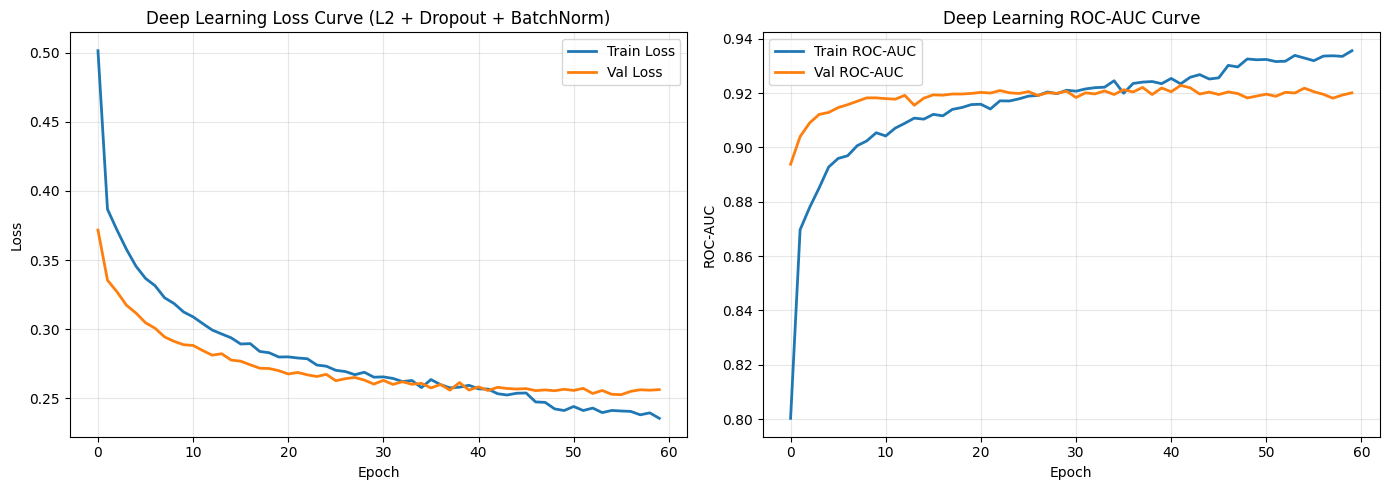

In [6]:
import tensorflow as tf
from tensorflow.keras import callbacks, layers, models, regularizers

# تنظيف الجلسة وتثبيت العشوائية لضمان ثبات النتائج
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)


# 1. بناء معمارية الشبكة العصبية العميقة (DL Lectures 1, 2, 3, 4)
def build_fintech_dl_model(input_dim):
  model = models.Sequential(
      [
          layers.Input(shape=(input_dim,)),
          # الطبقة المخفية الأولى (128 خلية)
          layers.Dense(
              128,
              kernel_initializer='he_normal',
              kernel_regularizer=regularizers.l2(1e-4),
          ),
          layers.BatchNormalization(),
          layers.Activation('relu'),
          layers.Dropout(0.30),
          # الطبقة المخفية الثانية (64 خلية)
          layers.Dense(
              64,
              kernel_initializer='he_normal',
              kernel_regularizer=regularizers.l2(1e-4),
          ),
          layers.BatchNormalization(),
          layers.Activation('relu'),
          layers.Dropout(0.25),
          # الطبقة المخفية الثالثة (32 خلية)
          layers.Dense(
              32,
              kernel_initializer='he_normal',
              kernel_regularizer=regularizers.l2(1e-4),
          ),
          layers.BatchNormalization(),
          layers.Activation('relu'),
          layers.Dropout(0.20),
          # طبقة الإخراج النهائية (خلية واحدة + Sigmoid للتصنيف الثنائي)
          layers.Dense(1, activation='sigmoid'),
      ],
      name='FinTech_Deep_Risk_Net',
  )

  model.compile(
      optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
      loss='binary_crossentropy',
      metrics=[
          'accuracy',
          tf.keras.metrics.AUC(name='auc'),
      ],
  )
  return model


dl_model = build_fintech_dl_model(X_train_final.shape[1])
dl_model.summary()

# 2. إعداد نظام المراقبة الآلي (Callbacks - DL Lecture 4)
cb_list = [
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
    callbacks.ModelCheckpoint(
        filepath='best_fintech_credit_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=0,
    ),
]

# 3. تدريب الشبكة العصبية
history = dl_model.fit(
    X_train_final,
    y_train,
    validation_data=(X_val_final, y_val),
    epochs=60,
    batch_size=64,
    callbacks=cb_list,
    verbose=1,
)

# 4. تقييم الشبكة على بيانات التحقق ومقارنتها بنماذج الـ ML
val_dl_probs = dl_model(X_val_final, training=False).numpy().ravel()
val_dl_preds = (val_dl_probs >= 0.50).astype(int)

print('\n=== أداء الشبكة العصبية العميقة على بيانات التحقق (Validation) ===')
print(f'Val Accuracy  : {accuracy_score(y_val, val_dl_preds)*100:.2f}%')
print(f'Val ROC-AUC   : {roc_auc_score(y_val, val_dl_probs):.4f}')
print(f'Val Precision : {precision_score(y_val, val_dl_preds)*100:.2f}%')
print(f'Val Recall    : {recall_score(y_val, val_dl_preds)*100:.2f}%')
print(f'Val F1-Score  : {f1_score(y_val, val_dl_preds):.4f}')

# 5. رسم منحنيات التعلم (Loss & ROC-AUC) لتشخيص التعميم
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_title('Deep Learning Loss Curve (L2 + Dropout + BatchNorm)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['auc'], label='Train ROC-AUC', linewidth=2)
axes[1].plot(history.history['val_auc'], label='Val ROC-AUC', linewidth=2)
axes[1].set_title('Deep Learning ROC-AUC Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('ROC-AUC')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== النتيجة النهائية على بيانات الاختبار المغلقة (Final Test Set Benchmark) ===
                     Model  Test_Acc (%)  Test_ROC_AUC  Test_Precision (%)  Test_Recall (%)  Test_F1
   Deep Learning (MLP Net)         92.49        0.9232               94.98            69.32   0.8015
        Random Forest (ML)         92.76        0.9269               94.30            71.23   0.8116
    Gradient Boosting (ML)         93.91        0.9493               96.80            74.61   0.8427
Hybrid AI Engine (ML + DL)         93.78        0.9452               97.74            73.27   0.8376

إجمالي الخسائر الكارثية لو وافق البنك على جميع القروض بدون ذكاء اصطناعي: $12,426,300.00

=== جدول تحسين عتبة القرار والأثر المالي للبنك (Cost-Sensitive Threshold Tuning) ===
 Threshold Test_Acc (%) Recall_Caught (%) Precision (%)  TP (متعثر أُمسك)  FN (متعثر فائت)  FP (إنذار مبكر) Net_Bank_Savings ($)
      0.55       93.80%            72.92%        98.29%              1034              384               18    

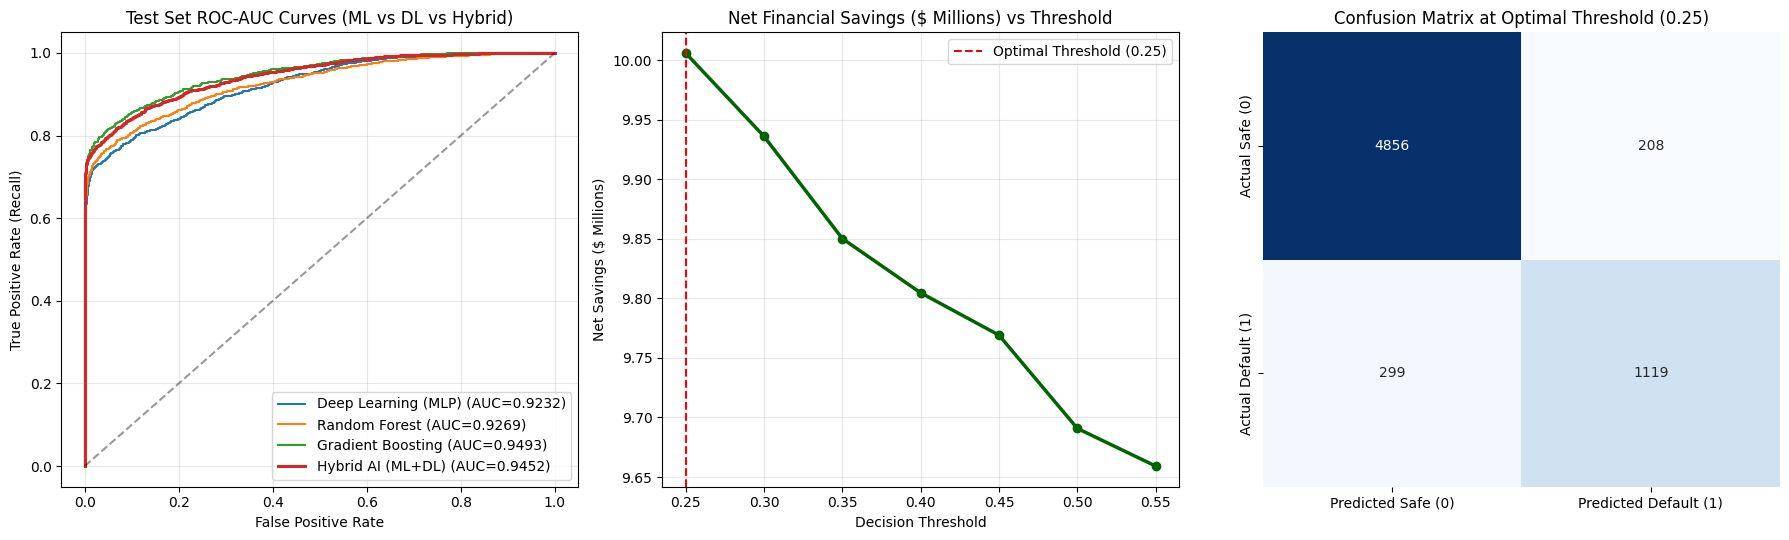

In [7]:
from sklearn.metrics import confusion_matrix, roc_curve

# 1. استخراج احتمالات التعثر على بيانات الاختبار المغلقة (Test Set - 6,482 قرضاً جديداً تماماً!)
test_gb_probs = trained_ml_models[
    '3. Gradient Boosting (Boosting)'
].predict_proba(X_test_final)[:, 1]
test_rf_probs = trained_ml_models['2. Random Forest (Bagging)'].predict_proba(
    X_test_final
)[:, 1]
test_dl_probs = dl_model(X_test_final, training=False).numpy().ravel()

# 2. ابتكار المحرك الهجين (Hybrid AI Ensemble: Gradient Boosting + Deep Learning + Random Forest)
test_hybrid_probs = (
    (0.55 * test_gb_probs) + (0.30 * test_dl_probs) + (0.15 * test_rf_probs)
)

# 3. مقارنة الأداء النهائي على بيانات الاختبار (Test Set) عند العتبة القياسية 0.50
test_comparison = []
for name, probs in [
    ('Deep Learning (MLP Net)', test_dl_probs),
    ('Random Forest (ML)', test_rf_probs),
    ('Gradient Boosting (ML)', test_gb_probs),
    ('Hybrid AI Engine (ML + DL)', test_hybrid_probs),
]:
  preds = (probs >= 0.50).astype(int)
  test_comparison.append({
      'Model': name,
      'Test_Acc (%)': round(accuracy_score(y_test, preds) * 100, 2),
      'Test_ROC_AUC': round(roc_auc_score(y_test, probs), 4),
      'Test_Precision (%)': round(precision_score(y_test, preds) * 100, 2),
      'Test_Recall (%)': round(recall_score(y_test, preds) * 100, 2),
      'Test_F1': round(f1_score(y_test, preds), 4),
  })

print(
    '=== النتيجة النهائية على بيانات الاختبار المغلقة (Final Test Set'
    ' Benchmark) ==='
)
print(pd.DataFrame(test_comparison).to_string(index=False))

# 4. حاسبة الأثر المالي للبنك بالدولار (Bank Financial ROI & Threshold Optimization)
# حساب التكلفة الحقيقية لكل قرض في بيانات الاختبار:
# - إذا كان القرض متعثراً وفاتنا كشفه (FN): يخسر البنك 80% من أصل مبلغ القرض (Loss Given Default = 80%)
# - إذا كان القرض سليماً ورفضناه خطأً (FP): يخسر البنك ربح الفائدة السنوية لذلك القرض (Opportunity Cost)
test_loan_amounts = X_test['loan_amnt'].values
test_interest_profits = test_loan_amounts * (
    X_test['loan_int_rate'].values / 100.0
)
total_possible_default_loss = np.sum(test_loan_amounts[y_test == 1] * 0.80)

print(
    '\nإجمالي الخسائر الكارثية لو وافق البنك على جميع القروض بدون ذكاء اصطناعي:'
    f' ${total_possible_default_loss:,.2f}'
)

threshold_analysis = []
for th in [0.55, 0.50, 0.45, 0.40, 0.35, 0.30, 0.25]:
  preds_th = (test_hybrid_probs >= th).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_test, preds_th).ravel()

  # الأموال التي أنقذها النموذج بإمساك المتعثرين (TP)
  saved_losses = np.sum(
      test_loan_amounts[(y_test == 1) & (preds_th == 1)] * 0.80
  )
  # الفوائد الضائعة بسبب التحفظ على عملاء سليمين (FP)
  missed_profits = np.sum(
      test_interest_profits[(y_test == 0) & (preds_th == 1)]
  )
  # صافي الوفر المالي للبنك
  net_financial_savings = saved_losses - missed_profits

  threshold_analysis.append({
      'Threshold': th,
      'Test_Acc (%)': f'{accuracy_score(y_test, preds_th)*100:.2f}%',
      'Recall_Caught (%)': f'{recall_score(y_test, preds_th)*100:.2f}%',
      'Precision (%)': f'{precision_score(y_test, preds_th)*100:.2f}%',
      'TP (متعثر أُمسك)': tp,
      'FN (متعثر فائت)': fn,
      'FP (إنذار مبكر)': fp,
      'Net_Bank_Savings ($)': f'${net_financial_savings:,.0f}',
      '_raw_savings': net_financial_savings,
  })

th_df = pd.DataFrame(threshold_analysis)
best_th_row = th_df.loc[th_df['_raw_savings'].idxmax()]
print(
    '\n=== جدول تحسين عتبة القرار والأثر المالي للبنك (Cost-Sensitive Threshold'
    ' Tuning) ==='
)
print(th_df.drop(columns=['_raw_savings']).to_string(index=False))
print(
    f"\n★ القرار المالي الأمثل للبنك: اختيار عتبة القرار (Threshold = {best_th_row['Threshold']}) "
    f"لتحقيق أعلى وفر مالي صافي قدره: {best_th_row['Net_Bank_Savings ($)']}"
)

# 5. رسم لوحة النشر الاحترافية لـ LinkedIn و GitHub (3 رسومات في لوحة واحدة)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# اللوحة 1: منحنيات ROC للمقارنة على بيانات الاختبار
for name, probs, color in [
    ('Deep Learning (MLP)', test_dl_probs, '#1f77b4'),
    ('Random Forest', test_rf_probs, '#2ca02c'),
    ('Gradient Boosting', test_gb_probs, '#ff7f0e'),
    ('Hybrid AI (ML+DL)', test_hybrid_probs, '#d62728'),
]:
  fpr, tpr, _ = roc_curve(y_test, probs)
  auc_val = roc_auc_score(y_test, probs)
  axes[0].plot(
      fpr,
      tpr,
      label=f'{name} (AUC={auc_val:.4f})',
      linewidth=2.2 if 'Hybrid' in name else 1.5,
  )
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set_title('Test Set ROC-AUC Curves (ML vs DL vs Hybrid)', fontsize=12)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# اللوحة 2: منحنى الوفر المالي الصافي بالدولار حسب عتبة القرار
axes[1].plot(
    th_df['Threshold'],
    th_df['_raw_savings'] / 1e6,
    marker='o',
    linewidth=2.5,
    color='darkgreen',
)
axes[1].axvline(
    best_th_row['Threshold'],
    color='red',
    linestyle='--',
    label=f"Optimal Threshold ({best_th_row['Threshold']})",
)
axes[1].set_title('Net Financial Savings ($ Millions) vs Threshold', fontsize=12)
axes[1].set_xlabel('Decision Threshold')
axes[1].set_ylabel('Net Savings ($ Millions)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# اللوحة 3: مصفوفة الارتباك عند العتبة المالية المثلى
best_th = best_th_row['Threshold']
cm_opt = confusion_matrix(y_test, (test_hybrid_probs >= best_th).astype(int))
sns.heatmap(
    cm_opt,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    ax=axes[2],
    xticklabels=['Predicted Safe (0)', 'Predicted Default (1)'],
    yticklabels=['Actual Safe (0)', 'Actual Default (1)'],
)
axes[2].set_title(
    f'Confusion Matrix at Optimal Threshold ({best_th})', fontsize=12
)

plt.tight_layout()
plt.savefig('fintech_executive_dashboard.png', dpi=300)
plt.show()

In [8]:
def evaluate_new_applicant(applicant_dict, optimal_threshold=0.25):
  # 1. تحويل بيانات المتقدم إلى DataFrame وتطبيق نفس خطوات الهندسة المالية
  app_df = pd.DataFrame([applicant_dict])
  app_df['emp_length_missing'] = 0
  app_df['int_rate_missing'] = 0
  app_fe = engineer_financial_features(app_df)

  # 2. الترميز ومطابقة الأعمدة مع بيانات التدريب
  cat_cols = [
      'person_home_ownership',
      'loan_intent',
      'loan_grade',
      'cb_person_default_on_file',
  ]
  base_cols = [
      c for c in X_train_enc.columns if not c.startswith('cluster_')
  ]
  app_enc = pd.get_dummies(app_fe, columns=cat_cols).reindex(
      columns=base_cols, fill_value=0
  )

  # 3. تحديد شريحة K-Means والتقييس النهائي
  app_scaled_1 = scaler.transform(app_enc)
  cluster_id = kmeans.predict(app_scaled_1)[0]
  for i in range(4):
    app_enc[f'cluster_{i}'] = int(cluster_id == i)

  app_final = final_scaler.transform(app_enc)

  # 4. حساب احتمالية التعثر عبر المحرك الهجين (ML + DL)
  p_gb = trained_ml_models['3. Gradient Boosting (Boosting)'].predict_proba(
      app_final
  )[0, 1]
  p_rf = trained_ml_models['2. Random Forest (Bagging)'].predict_proba(
      app_final
  )[0, 1]
  p_dl = float(dl_model(app_final, training=False).numpy().ravel()[0])
  p_hybrid = (0.55 * p_gb) + (0.30 * p_dl) + (0.15 * p_rf)

  decision = (
      'رفض / طلب ضمانات إضافية (HIGH RISK)'
      if p_hybrid >= optimal_threshold
      else 'موافقة فورية (APPROVED - LOW RISK)'
  )
  print(
      f"=== تقرير القرار الائتماني الذكي (الشريحة المكتشفة: Cluster {cluster_id}) ==="
  )
  print(
      f"الدخل: ${applicant_dict['person_income']:,} | القرض المطلوب:"
      f" ${applicant_dict['loan_amnt']:,} | التصنيف:"
      f" {applicant_dict['loan_grade']}"
  )
  print(
      f'احتمال التعثر -> [GradientBoosting: {p_gb*100:.1f}% | DeepLearning:'
      f' {p_dl*100:.1f}%] => المحرك الهجين: {p_hybrid*100:.1f}%'
  )
  print(f'القرار النهائي (عتبة {optimal_threshold}): {decision}\n')


# تجربة 1: عميل ذو دخل جيد ويطلب قرضاً مناسباً لتطوير مشروع
evaluate_new_applicant({
    'person_age': 32,
    'person_income': 85000,
    'person_home_ownership': 'MORTGAGE',
    'person_emp_length': 7.0,
    'loan_intent': 'VENTURE',
    'loan_grade': 'B',
    'loan_amnt': 10000,
    'loan_int_rate': 10.5,
    'loan_percent_income': 0.12,
    'cb_person_default_on_file': 'N',
    'cb_person_cred_hist_length': 8,
})

# تجربة 2: عميل مستأجر بدخل محدود يطلب قرضاً كبيراً بفائدة عالية لسداد ديون
evaluate_new_applicant({
    'person_age': 24,
    'person_income': 32000,
    'person_home_ownership': 'RENT',
    'person_emp_length': 1.0,
    'loan_intent': 'DEBTCONSOLIDATION',
    'loan_grade': 'E',
    'loan_amnt': 15000,
    'loan_int_rate': 16.8,
    'loan_percent_income': 0.47,
    'cb_person_default_on_file': 'Y',
    'cb_person_cred_hist_length': 2,
})

=== تقرير القرار الائتماني الذكي (الشريحة المكتشفة: Cluster 3) ===
الدخل: $85,000 | القرض المطلوب: $10,000 | التصنيف: B
احتمال التعثر -> [GradientBoosting: 0.4% | DeepLearning: 0.0%] => المحرك الهجين: 0.4%
القرار النهائي (عتبة 0.25): موافقة فورية (APPROVED - LOW RISK)

=== تقرير القرار الائتماني الذكي (الشريحة المكتشفة: Cluster 0) ===
الدخل: $32,000 | القرض المطلوب: $15,000 | التصنيف: E
احتمال التعثر -> [GradientBoosting: 99.9% | DeepLearning: 99.8%] => المحرك الهجين: 99.6%
القرار النهائي (عتبة 0.25): رفض / طلب ضمانات إضافية (HIGH RISK)



In [9]:
import os
import joblib
import zipfile

os.makedirs("exported_fintech_models", exist_ok=True)

# 1. حفظ الشبكة العصبية العميقة بصيغة Keras الرسمية
dl_model.save("exported_fintech_models/best_fintech_credit_model.keras")

# 2. حفظ نماذج تعلم الآلة وأدوات التجهيز و K-Means في حزمة واحدة
pipeline_bundle = {
    "gb_model": trained_ml_models["3. Gradient Boosting (Boosting)"],
    "rf_model": trained_ml_models["2. Random Forest (Bagging)"],
    "lr_model": trained_ml_models["1. Logistic Regression (Baseline)"],
    "imputer": imputer,
    "scaler": scaler,
    "kmeans": kmeans,
    "final_scaler": final_scaler,
    "feature_columns": list(X_train_enc.columns),
    "optimal_threshold": 0.25,
}
joblib.dump(pipeline_bundle, "exported_fintech_models/fintech_ml_pipeline.joblib")

# 3. ضغط النماذج في ملف واحد جاهز للتحميل من Output في Kaggle
with zipfile.ZipFile("fintech_trained_models_bundle.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write("exported_fintech_models/best_fintech_credit_model.keras")
    zf.write("exported_fintech_models/fintech_ml_pipeline.joblib")

print("تم حفظ وضغط جميع النماذج بنجاح في: fintech_trained_models_bundle.zip (جاهز للتحميل!)")

تم حفظ وضغط جميع النماذج بنجاح في: fintech_trained_models_bundle.zip (جاهز للتحميل!)
